# Ácidos: teoria, força e pH
### Funções inorgânicas — ácidos

**Objetivo:** Definir ácido nas visões de Arrhenius e Brønsted–Lowry, medir a força com $K_a$ e $\mathrm{p}K_a$ e comparar o pH de um ácido forte com o de um fraco.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Um **ácido**, no sentido de Arrhenius, é toda substância que, em água, libera o cátion hidrogênio $\mathrm{H^+}$ (na prática, o íon hidrônio $\mathrm{H_3O^+}$). No sentido de Brønsted–Lowry, mais amplo, ácido é toda espécie **doadora de próton**:

$$
\boxed{\mathrm{HA + H_2O \rightleftharpoons H_3O^+ + A^-}}
$$

O par $\mathrm{HA/A^-}$ é um **par conjugado**: quanto mais forte o ácido, mais fraca é sua base conjugada. A força do ácido é medida pela constante de acidez

$$
K_a = \frac{[\mathrm{H_3O^+}][\mathrm{A^-}]}{[\mathrm{HA}]}, \qquad \mathrm{p}K_a = -\log_{10} K_a
$$

Três consequências que valem para todo o resto do assunto:

- $\mathrm{p}K_a$ pequeno (ou negativo) → ácido **forte** (HCl, $\mathrm{p}K_a \approx -6$); $\mathrm{p}K_a$ entre 2 e 5 → ácido **fraco** (acético, 4,76).
- Ácido forte ioniza praticamente 100%; ácido fraco ioniza pouco e o equilíbrio fica à esquerda.
- **Ácido + base → sal + água** (neutralização), por exemplo $\mathrm{HCl + NaOH \rightarrow NaCl + H_2O}$.

## 2. Exemplo resolvido passo a passo

Comparar dois ácidos de mesma concentração, $c = 0{,}100\ \mathrm{mol/L}$: o ácido clorídrico (forte) e o ácido acético (fraco, $K_a = 1{,}8\times10^{-5}$).

**Passo 1 — HCl, ácido forte (ionização total).**

$$
[\mathrm{H_3O^+}] = c = 0{,}100\ \mathrm{mol/L}
\qquad\Rightarrow\qquad
\mathrm{pH} = -\log_{10}0{,}100 = \boxed{1{,}00}
$$

**Passo 2 — ácido acético, ácido fraco (aproximação $\sqrt{K_a c}$).**

$$
[\mathrm{H_3O^+}] \approx \sqrt{K_a\,c} = \sqrt{1{,}8\times10^{-5}\cdot 0{,}100} = 1{,}34\times10^{-3}\ \mathrm{mol/L}
$$

$$
\mathrm{pH} = -\log_{10}(1{,}34\times10^{-3}) = \boxed{2{,}87}
$$

**Passo 3 — grau de ionização $\alpha$.**

$$
\alpha_{\mathrm{HA}} = \frac{[\mathrm{H_3O^+}]}{c} = \frac{1{,}34\times10^{-3}}{0{,}100} = 1{,}34\%
$$

Ou seja: o ácido forte está 100% ionizado e o fraco apenas 1,3% — daí a diferença de quase 2 unidades de pH.

## 3. Conferindo o cálculo com Python

A próxima célula reproduz as duas contas com as mesmas grandezas do exemplo.

In [2]:
# @title Força de ácidos: pH e grau de ionização
import math

C = 0.100          # mol/L
KA = 1.8e-5        # ácido acético

def ph_acido_forte(concentracao):
    """Ácido forte: ioniza 100% (monoprótico)."""
    return -math.log10(concentracao)

def ph_acido_fraco(concentracao, ka):
    """Ácido fraco: [H+] ~ raiz(Ka*c) — vale quando a ionização é pequena."""
    h = math.sqrt(ka * concentracao)
    return -math.log10(h), h

pH_forte = ph_acido_forte(C)
pH_fraco, h_fraco = ph_acido_fraco(C, KA)

print(f"Concentração:        {C:.3f} mol/L")
print(f"pH do HCl (forte):   {pH_forte:.2f}")
print(f"pH do CH3COOH (fraco): {pH_fraco:.2f}")
print(f"[H+] do acético:     {h_fraco:.2e} mol/L")
print(f"Grau de ionização:   {100 * h_fraco / C:.2f} %")
print(f"pKa do acético:      {-math.log10(KA):.2f}")

Concentração:        0.100 mol/L
pH do HCl (forte):   1.00
pH do CH3COOH (fraco): 2.87
[H+] do acético:     1.34e-03 mol/L
Grau de ionização:   1.34 %
pKa do acético:      4.74


## 4. Visualização

### 4.1 O ácido clorídrico em 3D — arraste para girar

O HCl é diatômico: uma ligação covalente polar entre H e Cl. Em água, essa ligação se rompe por heterólise e o próton é transferido para a água.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("Cl")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 O ácido acético em 3D

Compare a geometria: o carbono da carboxila é trigonal plano (120°) e o $\mathrm{CH_3}$ é tetraédrico (109,5°). Gire a figura para ver os dois planos.

In [4]:
molecula_3d("CC(=O)O")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 As duas estruturas em 2D, com os risquinhos

No desenho 2D, **um** traço é ligação simples e **dois** são ligação dupla — o $\mathrm{C=O}$ da carboxila aparece com o risco duplo. O H do grupo $-OH$ aparece porque é exatamente ele que sai na ionização.

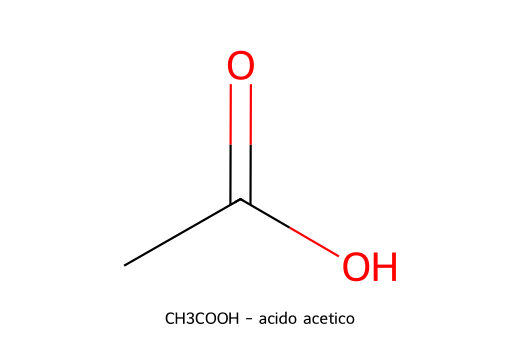

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("Cl", legenda="HCl - acido cloridrico")
estrutura_2d("CC(=O)O", legenda="CH3COOH - acido acetico")

### 4.4 Galeria de ácidos comuns

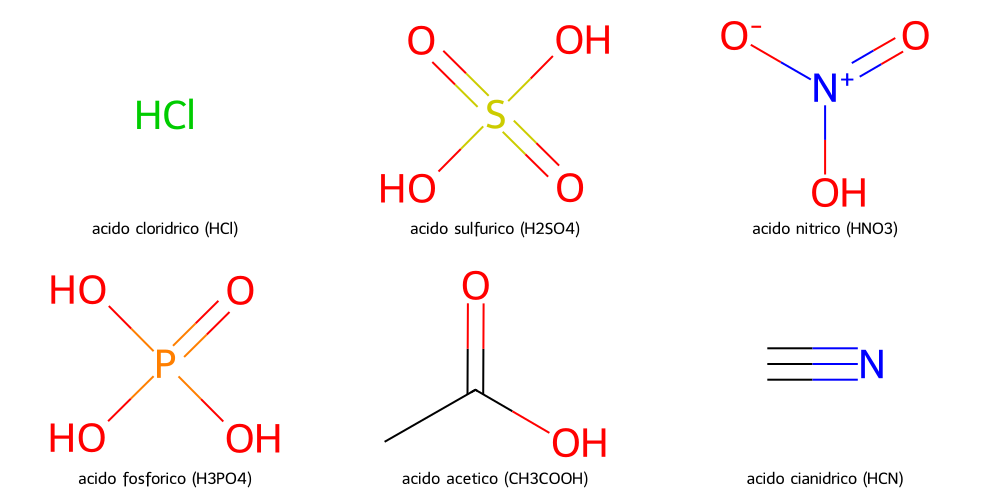

In [6]:
# @title Galeria 2D: compare as espécies lado a lado
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

especies = [
    ("acido cloridrico (HCl)", "Cl"),
    ("acido sulfurico (H2SO4)", "OS(=O)(=O)O"),
    ("acido nitrico (HNO3)", "O[N+](=O)[O-]"),
    ("acido fosforico (H3PO4)", "OP(=O)(O)O"),
    ("acido acetico (CH3COOH)", "CC(=O)O"),
    ("acido cianidrico (HCN)", "C#N"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in especies],
                              molsPerRow=3, subImgSize=(330, 250),
                              legends=[nome for nome, _ in especies], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)   # funciona com e sem IPython

### 4.5 pH × concentração: forte contra fraco

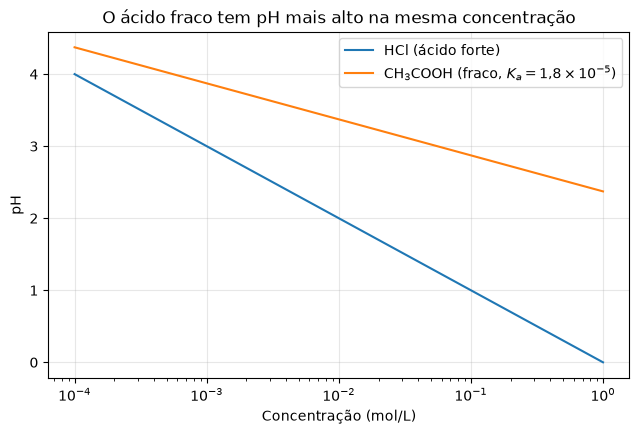

In [7]:
# @title Curvas de pH
import numpy as np
import matplotlib.pyplot as plt

concentracoes = np.logspace(-4, 0, 80)          # de 0,0001 a 1 mol/L
plt.figure(figsize=(7.5, 4.5))
plt.plot(concentracoes, -np.log10(concentracoes), label="HCl (ácido forte)")
plt.plot(concentracoes, -np.log10(np.sqrt(KA * concentracoes)), label="CH$_3$COOH (fraco, $K_a=1{,}8\\times10^{-5}$)")
plt.xscale("log")
plt.xlabel("Concentração (mol/L)")
plt.ylabel("pH")
plt.title("O ácido fraco tem pH mais alto na mesma concentração")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 4.6 Força relativa: escala de $\mathrm{p}K_a$

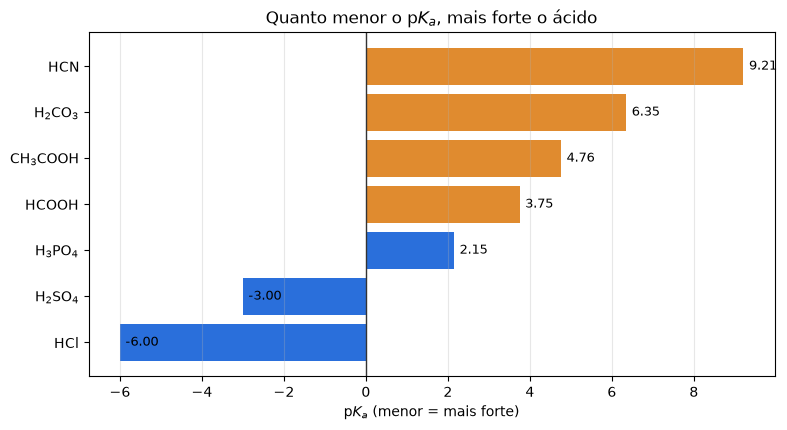

In [8]:
# @title pKa dos ácidos do dia a dia
acidos = ["HCl", "H$_2$SO$_4$", "H$_3$PO$_4$", "HCOOH", "CH$_3$COOH", "H$_2$CO$_3$", "HCN"]
pkas = [-6.0, -3.0, 2.15, 3.75, 4.76, 6.35, 9.21]

plt.figure(figsize=(8, 4.4))
cores = ["#2a6fdb" if p < 3 else "#e08b2f" for p in pkas]
plt.barh(acidos, pkas, color=cores)
for i, valor in enumerate(pkas):
    plt.annotate(f"{valor:.2f}", (valor, i), xytext=(4, 0), textcoords="offset points",
                 va="center", fontsize=9)
plt.axvline(0, color="#333", linewidth=1)
plt.xlabel("p$K_a$ (menor = mais forte)")
plt.title("Quanto menor o p$K_a$, mais forte o ácido")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- O HCl aparece como **forte** ($\mathrm{p}K_a$ negativo) e o acético como **fraco**: a diferença entre eles é de cerca de 11 ordens de grandeza em $K_a$.
- Na curva de pH, as duas linhas se aproximam quando a solução fica muito diluída: em concentração minúscula até o ácido fraco ioniza "quase tudo", e a distinção perde sentido prático.
- O grau de ionização é a leitura mais direta de "força": $100\%$ para forte, poucos por cento para fraco.
- Em prova, o erro clássico é aplicar $\sqrt{K_a c}$ em ácido forte (ou usar $[\mathrm{H^+}] = c$ em ácido fraco). Primeiro identifique a força; depois escolha a fórmula.

## 6. Exercício de fixação

Um ácido fraco monoprótico tem $K_a = 4{,}0\times10^{-6}$ e foi preparado a $0{,}050\ \mathrm{mol/L}$. Qual é o pH e qual é o grau de ionização?

Tente prever antes de executar a célula.

In [9]:
# @title Exercício
KA_EX, C_EX = 4.0e-6, 0.050
pH_ex, h_ex = ph_acido_fraco(C_EX, KA_EX)
print(f"[H+] = {h_ex:.2e} mol/L")
print(f"pH = {pH_ex:.2f}")
print(f"grau de ionização = {100 * h_ex / C_EX:.2f} %")
print(f"pKa = {-math.log10(KA_EX):.2f}")

[H+] = 4.47e-04 mol/L
pH = 3.35
grau de ionização = 0.89 %
pKa = 5.40


## 7. Resumo

- Ácido de Arrhenius libera $\mathrm{H^+}$ em água; de Brønsted–Lowry **doa próton**.
- $K_a$ e $\mathrm{p}K_a$ medem a força; menor $\mathrm{p}K_a$ = ácido mais forte.
- Ácido forte: $[\mathrm{H^+}] = c$. Ácido fraco: $[\mathrm{H^+}] \approx \sqrt{K_a c}$.
- $\mathrm{pH} = -\log[\mathrm{H^+}]$ e o grau de ionização é $\alpha = [\mathrm{H^+}]/c$.
- Todo ácido tem uma base conjugada; juntos formam um par conjugado.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- IUPAC. *Compendium of Chemical Terminology* (Gold Book).
- FELTRE, R. *Química Geral*. Moderna.